In [ ]:
# 安装必要的库（如果尚未安装）
# !pip install pandas matplotlib seaborn wordcloud transformers nltk

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
from transformers import AutoTokenizer
import re
import nltk
from nltk.corpus import stopwords

# 下载NLTK停用词
nltk.download('stopwords')

# 设置绘图风格和中文字体（如果标题/摘要包含中文，NAIP主要是英文，这里以英文为主）
plt.style.use('seaborn-v0_8-whitegrid')

/Users/ruyi/.pyenv/versions/naip/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[nltk_data] Downloading package stopwords to /Users/ruyi/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [2]:
# 假设你的数据集路径如下，参考官方代码中的路径结构
data_path = '/Users/ruyi/Desktop/NAIP/dataset/naip_box.csv' 

# 读取CSV文件
df = pd.read_csv(data_path)

# 检查是否包含 title 和 abstract 列
if 'title' in df.columns and 'abstract' in df.columns:
    print("成功加载包含 title 和 abstract 的数据！共 {} 条记录。".format(len(df)))
else:
    print("请检查CSV文件，确保包含 'title' 和 'abstract' 列。")

def clean_text(text):
    """
    清洗文本：去除换行符、LaTeX符号等特殊格式，这符合NAIP作者的建议。
    """
    if not isinstance(text, str):
        return ""
    # 去除换行符
    text = text.replace('\n', ' ').replace('\r', '')
    # 简单的去除LaTeX数学公式符号 $...$
    text = re.sub(r'\$.*?\$', '', text)
    # 去除多余空格
    text = re.sub(r'\s+', ' ', text).strip()
    return text

# 拼接 title 和 abstract，并进行清洗
df['combined_text'] = df.apply(lambda row: f"Title: {clean_text(row['title'])} Abstract: {clean_text(row['abstract'])}", axis=1)

print("文本拼接与清洗完成！示例：")
print(df['combined_text'].iloc[0][:200] + "...")

成功加载包含 title 和 abstract 的数据！共 3906 条记录。
文本拼接与清洗完成！示例：
Title: Empathetic Response Generation via Emotion Cause Transition Graph Abstract: Empathetic dialogue is a human-like behavior that requires the perception of both affective factors (e.g., emotion st...


/Users/ruyi/.pyenv/versions/naip/lib/python3.10/site-packages/huggingface_hub/file_download.py:1132: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Token indices sequence length is longer than the specified maximum sequence length for this model (522 > 512). Running this sequence through the model will result in indexing errors


平均 Token 数量: 282.12
最大 Token 数量: 2579
最小 Token 数量: 21


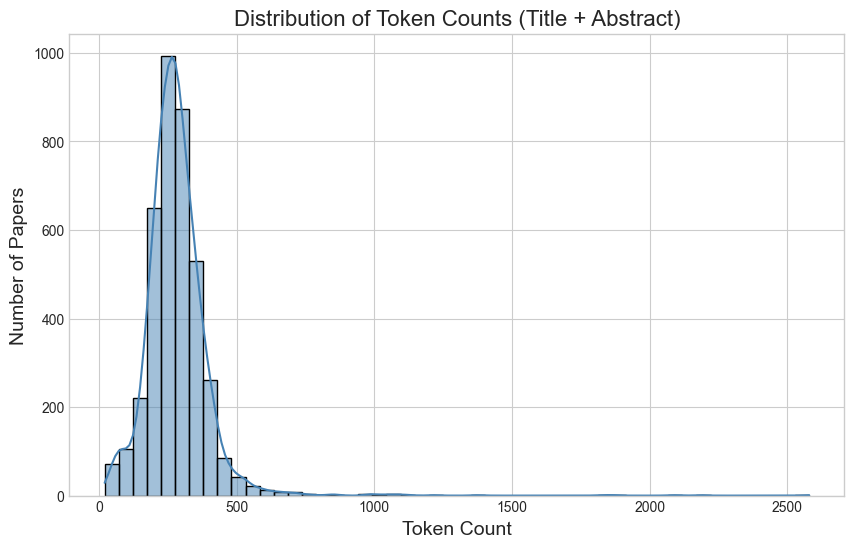

In [3]:
# 加载 LLaMA-3 的 Tokenizer (需要Hugging Face权限，或者使用基础的GPT-2/BERT tokenizer代替测试)
# 这里以 bert-base-uncased 为例进行快速演示，如果你有llama3的权重路径，可以替换为llama3的路径
tokenizer_name = "bert-base-uncased" 
tokenizer = AutoTokenizer.from_pretrained(tokenizer_name)

# 计算每段拼接文本的 Token 数量
df['token_count'] = df['combined_text'].apply(lambda x: len(tokenizer.encode(x, truncation=False)))

print(f"平均 Token 数量: {df['token_count'].mean():.2f}")
print(f"最大 Token 数量: {df['token_count'].max()}")
print(f"最小 Token 数量: {df['token_count'].min()}")

# 绘制 Token 数量分布直方图 (类似于幽默论文中的图2-2)
plt.figure(figsize=(10, 6))
sns.histplot(df['token_count'], bins=50, kde=True, color='steelblue')
plt.title('Distribution of Token Counts (Title + Abstract)', fontsize=16)
plt.xlabel('Token Count', fontsize=14)
plt.ylabel('Number of Papers', fontsize=14)
plt.show()

In [15]:
import matplotlib.font_manager as fm

# 打印所有字体
for font in fm.findSystemFonts(fontpaths=None, fontext='ttf'):
    print(font)

huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


/System/Library/AssetsV2/com_apple_MobileAsset_Font7/12cc699be28fb04f3e3c4969a0378a87b920b174.asset/AssetData/BMHannaAir-Regular.otf
/System/Library/AssetsV2/com_apple_MobileAsset_Font7/0ab217c39c45c7c6acaddfa199fd32c55a7b4a19.asset/AssetData/ToppanBunkyuGothicPr6N.ttc
/System/Library/AssetsV2/com_apple_MobileAsset_Font7/6fe206600409e98dcd3e18af1427806070d0150f.asset/AssetData/ArimaKoshi.ttc
/System/Library/Fonts/NewYork.ttf
/System/Library/Fonts/Supplemental/NotoSansNewa-Regular.ttf
/System/Library/Fonts/Supplemental/NotoSansDuployan-Regular.ttf
/System/Library/AssetsV2/com_apple_MobileAsset_Font7/54ef167d6c8e99a69a0d41ce252cc5995ba47580.asset/AssetData/YuGothic-Medium.otf
/System/Library/Fonts/Supplemental/Courier New.ttf
/System/Library/Fonts/Supplemental/Trebuchet MS Italic.ttf
/System/Library/AssetsV2/com_apple_MobileAsset_Font7/4cec0fab93a88d2448fed090966ef489adb6cfcc.asset/AssetData/Baijam.ttc
/System/Library/Fonts/Supplemental/STIXNonUniBolIta.otf
/System/Library/AssetsV2/com_a

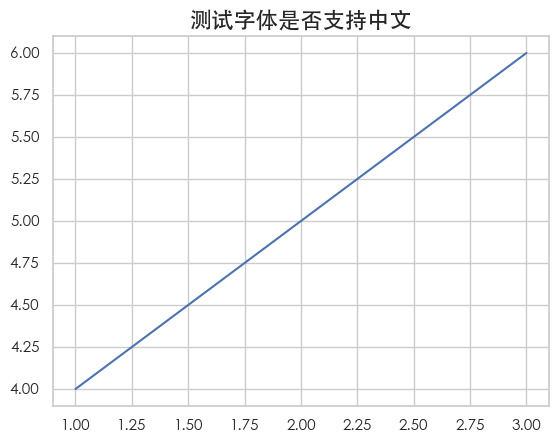

In [24]:
import matplotlib.pyplot as plt
from matplotlib import rcParams

# 直接设置字体名称
rcParams['font.family'] = 'STHeiti'

# 测试绘图
plt.title("测试字体是否支持中文", fontsize=16)
plt.plot([1, 2, 3], [4, 5, 6])  # 示例数据
plt.show()

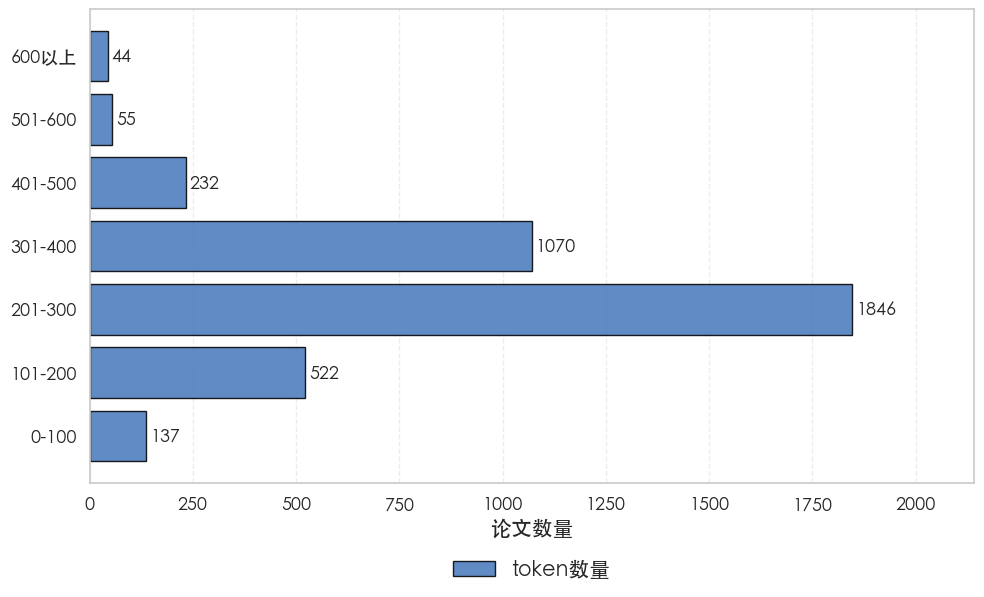

In [40]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from matplotlib import rcParams

# 全局设置为 STHeiti（中文支持字体）
rcParams['font.family'] = 'STHeiti'

# 手工设置分组
bins = [0, 100, 200, 300, 400, 500, 600, np.inf]
labels = ['0-100', '101-200', '201-300', '301-400', '401-500', '501-600', '600以上']

# 假设 DataFrame 已经存在 token_count 列
df['分组'] = pd.cut(df['token_count'], bins=bins, labels=labels, right=True, include_lowest=True)
group_counts = df['分组'].value_counts(sort=False)

plt.figure(figsize=(10, 6))
# bars = plt.barh(labels, group_counts, color='#4B7BBC', edgecolor='black', alpha=0.88)
bars = plt.barh(labels, group_counts, color='#4B7BBC', edgecolor='black', alpha=0.88, label='token数量')

# plt.legend(loc='lower center', fontsize=15, frameon=False, bbox_to_anchor=(0.5, -0.08), ncol=1)
plt.xlabel('论文数量', fontsize=15)
# plt.ylabel('Token数量区间', fontsize=15)
# plt.title('图2-2 Token数量分布', fontsize=18, pad=12, weight='bold')
plt.xlim(0, group_counts.max() * 1.16)
plt.xticks(fontsize=13)
plt.yticks(fontsize=13)
for bar in bars:
    plt.text(bar.get_width() + 10, bar.get_y() + bar.get_height()/2,
             int(bar.get_width()), va='center', fontsize=13)
plt.grid(axis='x', linestyle='--', alpha=0.35)
plt.grid(axis='y', visible=False)   
plt.legend(
    loc='upper center',
    fontsize=15,
    frameon=False,
    bbox_to_anchor=(0.5, -0.12),
    ncol=1
)

plt.tight_layout()
plt.subplots_adjust(bottom=0.18)   # 给底部多留点空间

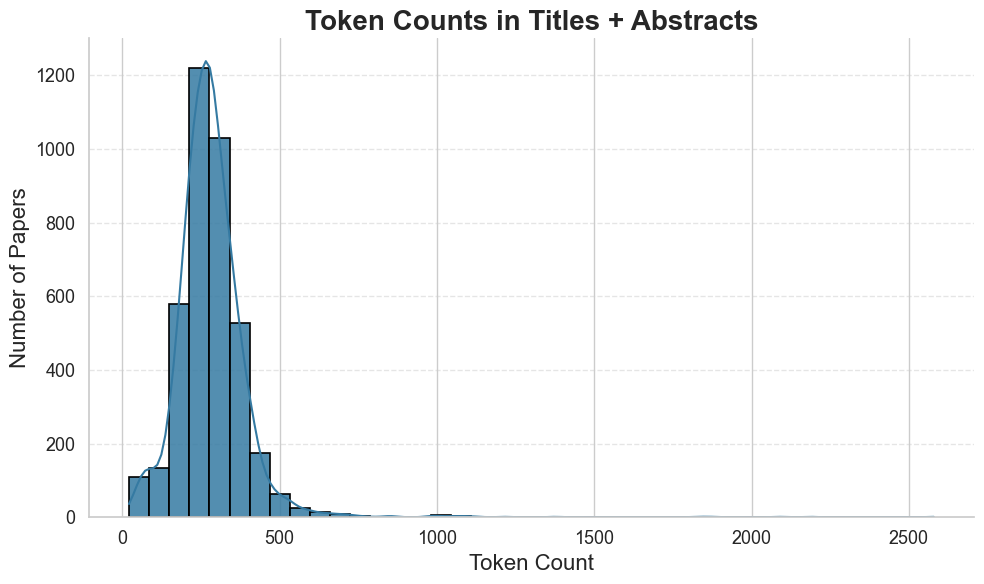

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")  # 设置白色网格主题
# 颜色用精致一些的调色板
color = sns.color_palette("mako_r", 1)[0]
sns.histplot(df['token_count'], bins=40, kde=True,
             color=color, edgecolor='black', linewidth=1.2, alpha=0.85)

plt.title('Token Counts in Titles + Abstracts', fontsize=20, fontweight='bold', fontname='Arial')
plt.xlabel('Token Count', fontsize=16, fontname='Arial')
plt.ylabel('Number of Papers', fontsize=16, fontname='Arial')
plt.xticks(fontsize=13, fontname='Arial')
plt.yticks(fontsize=13, fontname='Arial')
plt.grid(axis='y', linestyle='--', alpha=0.5)
sns.despine()  # 去掉右上两条边界线
plt.tight_layout()
plt.show()

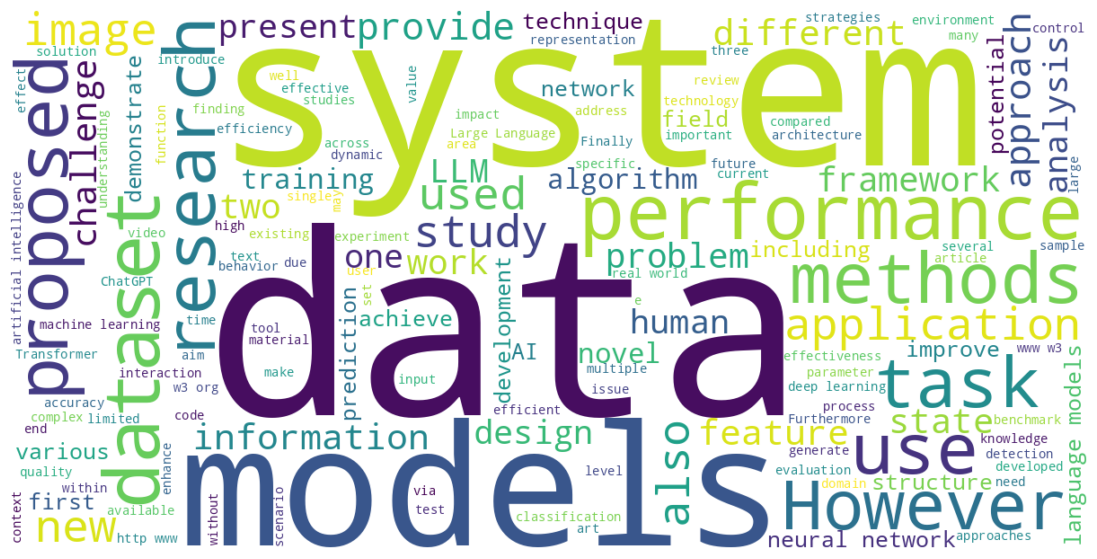

In [32]:
# 提取所有文本用于词频统计
all_text = " ".join(df['combined_text'].tolist())

# 获取英文停用词，并加入一些常见的无意义词汇（如论文中常出现的词）
stop_words = set(stopwords.words('english'))
additional_stopwords = {'Title', 'Abstract', 'paper', 'propose', 'method', 'model', 'results', 'show', 'using', 'based'}
stop_words = stop_words.union(additional_stopwords)

# 生成词云 (类似于幽默论文中的图2-3)
wordcloud = WordCloud(
    width=1200, 
    height=600, 
    background_color='white',
    stopwords=stop_words,
    max_words=150,
    colormap='viridis'
).generate(all_text)

# 显示词云图
plt.figure(figsize=(14, 7))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
# plt.title('Word Cloud of Titles and Abstracts in NAID Dataset', fontsize=18)
plt.show()